In [ ]:
%pip install scipy scikit-learn matplotlib numpy pandas seaborn

  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/36.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.5 MB ? eta -:--:--
   - -------------------------------------- 1.0/36.5 MB 2.1 MB/s eta 0:00:17
   - -------------------------------------- 1.6/36.5 MB 2.2 MB/s eta 0:00:16
   -- ------------------------------------- 2.1/36.5 MB 2.3 MB/s eta 0:00:15
   -- ------------------------------------- 2.6/36.5 MB 2.3 MB/s eta 0:00:15
   --- ------------------------------------ 3.4/36.5 MB 2.5 MB/s eta 0:00:14
   ---- ----------------------------------- 3.9/36.5 MB 2.5 MB/s eta 0:00:13
   ---- ----------------------------------- 4.5/36.5 MB 2.6 MB/s eta 0:00:13
   ----- ---------------------------------- 5.0/3


[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: C:\Users\Hughe\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import glob
import os

# Get all CSV files from both directories
files_1 = glob.glob('mod-PM068_2024/**/*.csv', recursive=True) + glob.glob('mod-PM068_2024/*.csv')
files_2 = glob.glob('mod-PM068_2025/**/*.csv', recursive=True) + glob.glob('mod-PM068_2024/*.csv')

# Combine file lists and remove duplicates
all_files = list(set(files_1 + files_2))

# Read and merge all CSV files
df_list = [pd.read_csv(f) for f in all_files]

sensor_df = pd.concat(df_list)

print(f"Total files merged: {len(all_files)}")
print(f"Merged DataFrame shape: {sensor_df.shape}")


Total files merged: 24
Merged DataFrame shape: (946850, 55)


In [ ]:
sensor_df

,timestamp_local,id,sn,sample_rh,sample_temp,sample_pres,bin0,bin1,bin2,bin3,...,flag,lat,lon,device_state,pm1,pm25,pm10,pm1_model_id,pm25_model_id,pm10_model_id
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:02+00:00,2024-01-01T00:00:02Z,446580062,MOD-PM-01068,76.56,29.33,0.0,23.256,4.430,2.426,0.873,...,0,5.65136,-0.18566,ACTIVE,26.299,37.781,133.534,9434.0,9435.0,9436.0
2024-01-01 00:01:02+00:00,2024-01-01T00:01:02Z,446580064,MOD-PM-01068,76.60,29.33,0.0,24.364,4.635,2.360,0.848,...,0,5.65136,-0.18566,ACTIVE,26.195,38.975,112.321,9434.0,9435.0,9436.0
2024-01-01 00:02:02+00:00,2024-01-01T00:02:02Z,446580063,MOD-PM-01068,76.65,29.34,0.0,23.497,4.614,2.405,0.857,...,0,5.65136,-0.18566,ACTIVE,26.323,38.784,133.536,9434.0,9435.0,9436.0
2024-01-01 00:03:02+00:00,2024-01-01T00:03:02Z,446580061,MOD-PM-01068,76.65,29.34,0.0,23.915,4.517,2.555,0.811,...,0,5.65136,-0.18566,ACTIVE,25.931,36.756,118.861,9434.0,9435.0,9436.0
2024-01-01 00:04:02+00:00,2024-01-01T00:04:02Z,446580143,MOD-PM-01068,76.66,29.33,0.0,23.830,4.592,2.219,0.748,...,0,5.65136,-0.18566,ACTIVE,25.209,37.397,126.208,9434.0,9435.0,9436.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-31 23:55:15+00:00,2025-12-31T23:55:15Z,974153165,MOD-PM-01068,74.49,27.51,0.0,21.182,1.155,0.355,0.081,...,0,5.65136,-0.18566,ACTIVE,36.709,38.060,50.170,9434.0,9435.0,9436.0
2025-12-31 23:56:15+00:00,2025-12-31T23:56:15Z,974153167,MOD-PM-01068,74.58,27.51,0.0,20.527,1.181,0.302,0.086,...,0,5.65136,-0.18566,ACTIVE,35.932,37.068,46.637,9434.0,9435.0,9436.0
2025-12-31 23:57:15+00:00,2025-12-31T23:57:15Z,974153166,MOD-PM-01068,74.80,27.50,0.0,20.495,1.066,0.308,0.112,...,0,5.65136,-0.18566,ACTIVE,37.705,38.811,43.126,9434.0,9435.0,9436.0


In [ ]:
sensor_df['timestamp'] = pd.to_datetime(sensor_df['timestamp'], errors='coerce')

display(sensor_df['timestamp'].dt.month.unique())

array([ 9,  4,  3, 11,  7,  8,  2,  6,  1,  5, 12, 10])

In [ ]:
sensor_df.set_index('timestamp', inplace=True)

In [ ]:
display(sensor_df.index.month.unique())

Index([9, 4, 3, 11, 7, 8, 2, 6, 1, 5, 12, 10], dtype='int32', name='timestamp')

In [ ]:
sensor_df.sort_index(inplace=True)

In [ ]:
sensor_df.columns

Index(['timestamp_local', 'id', 'sn', 'sample_rh', 'sample_temp', 'sample_pres', 'bin0', 'bin1', 'bin2', 'bin3', 'bin4', 'bin5', 'bin6', 'bin7', 'bin8',
       'bin9', 'bin10', 'bin11', 'bin12', 'bin13', 'bin14', 'bin15', 'bin16', 'bin17', 'bin18', 'bin19', 'bin20', 'bin21', 'bin22', 'bin23', 'opcn3_temp',
       'opcn3_rh', 'opcn3_pm1', 'opcn3_pm25', 'opcn3_pm10', 'pm1_env', 'pm25_env', 'pm10_env', 'neph_bin0', 'neph_bin1', 'neph_bin2', 'neph_bin3', 'neph_bin4',
       'neph_bin5', 'flag', 'lat', 'lon', 'device_state', 'pm1', 'pm25', 'pm10', 'pm1_model_id', 'pm25_model_id', 'pm10_model_id'],
      dtype='object')

In [ ]:
sensor_df['pm25'] = pd.to_numeric(sensor_df['pm25'], errors='coerce')
sensor_df.dropna(subset=['pm25'], inplace=True)
sensor_hourly = sensor_df[['pm25', 'sample_rh', 'sample_temp']].resample('1H').mean()

# Show percentage of valid values
(sensor_df['pm25'].notna().sum() / len(sensor_df) * 100)

100.0

In [ ]:
ref_df = pd.read_csv('Teledyne_T640/2024-2026 T640.csv')
ref_df = ref_df.rename(columns={'Timestamp (UTC+0)': 'timestamp'})

In [ ]:
ref_df['timestamp'] = pd.to_datetime(ref_df['timestamp'], errors='coerce', utc=True)
ref_df.set_index('timestamp', inplace=True)


In [ ]:
# reduces accuracy but removes outliers that could skew the model.

import numpy as np
from scipy import stats

# z_scores = np.abs(stats.zscore(sensor_hourly['pm25'].dropna()))
# outliers = sensor_hourly['pm25'].index[z_scores > 3]
# sensor_hourly = sensor_hourly.drop(outliers)

ref_z_scores = np.abs(stats.zscore(ref_df['PM25'].dropna()))
ref_outliers = ref_df['PM25'].index[ref_z_scores > 3]
ref_df = ref_df.drop(ref_outliers)

len(ref_outliers)



395

In [ ]:
## Presence

Sensor_presence = sensor_hourly['pm25'].notna().astype(int)
Reference_presence = ref_df['PM25'].notna().astype(int)

print(Sensor_presence.value_counts(normalize=True) * 100)
print(Reference_presence.value_counts(normalize=True) * 100)

pm25
1    80.603055
0    19.396945
Name: proportion, dtype: float64
PM25
1    100.0
Name: proportion, dtype: float64


In [ ]:
merged_df = pd.merge(sensor_hourly, ref_df['PM25'], left_index=True, right_index=True, how='inner')

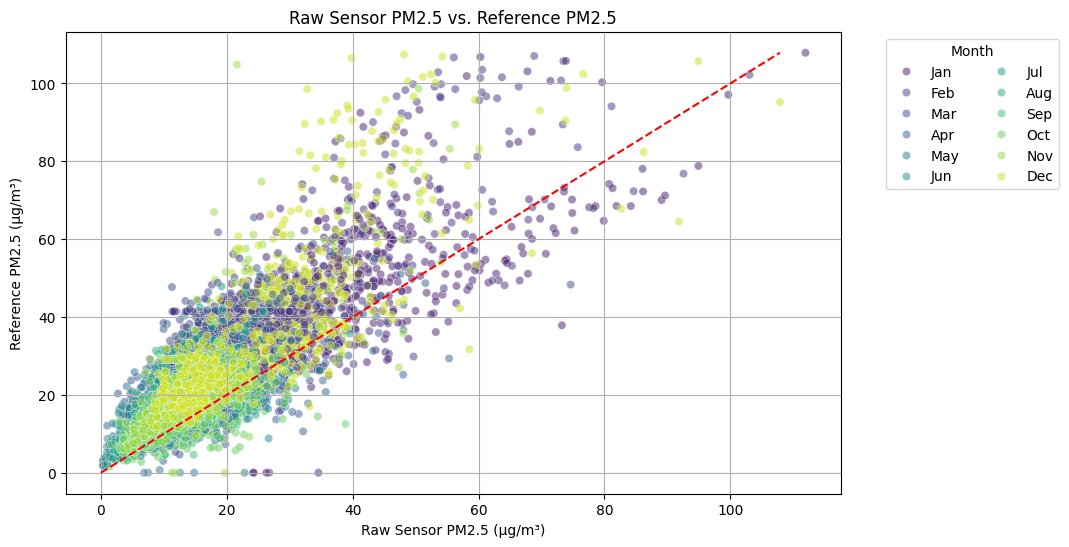

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(10, 6))
ax = sns.scatterplot(
    data=merged_df,
    x='pm25',
    y='PM25',
    hue=merged_df.index.month,
    hue_order=range(1, 13),
    palette=sns.color_palette('viridis', 12),
    alpha=0.5
)

plt.xlabel('Raw Sensor PM2.5 (µg/m³)')
plt.ylabel('Reference PM2.5 (µg/m³)')
plt.plot(
    [merged_df['PM25'].min(), merged_df['PM25'].max()],
    [merged_df['PM25'].min(), merged_df['PM25'].max()],
    'r--'
)
plt.title('Raw Sensor PM2.5 vs. Reference PM2.5')

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles[:12], month_names, title='Month', ncol=2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('raw_pm25_scatter.png', dpi=700)
plt.grid(True)
plt.show()



In [ ]:
sensor_df.columns

Index(['timestamp_local', 'id', 'sn', 'sample_rh', 'sample_temp', 'sample_pres', 'bin0', 'bin1', 'bin2', 'bin3', 'bin4', 'bin5', 'bin6', 'bin7', 'bin8',
       'bin9', 'bin10', 'bin11', 'bin12', 'bin13', 'bin14', 'bin15', 'bin16', 'bin17', 'bin18', 'bin19', 'bin20', 'bin21', 'bin22', 'bin23', 'opcn3_temp',
       'opcn3_rh', 'opcn3_pm1', 'opcn3_pm25', 'opcn3_pm10', 'pm1_env', 'pm25_env', 'pm10_env', 'neph_bin0', 'neph_bin1', 'neph_bin2', 'neph_bin3', 'neph_bin4',
       'neph_bin5', 'flag', 'lat', 'lon', 'device_state', 'pm1', 'pm25', 'pm10', 'pm1_model_id', 'pm25_model_id', 'pm10_model_id'],
      dtype='object')

In [ ]:
merged_df.index.month.unique()

Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype='int32', name='timestamp')

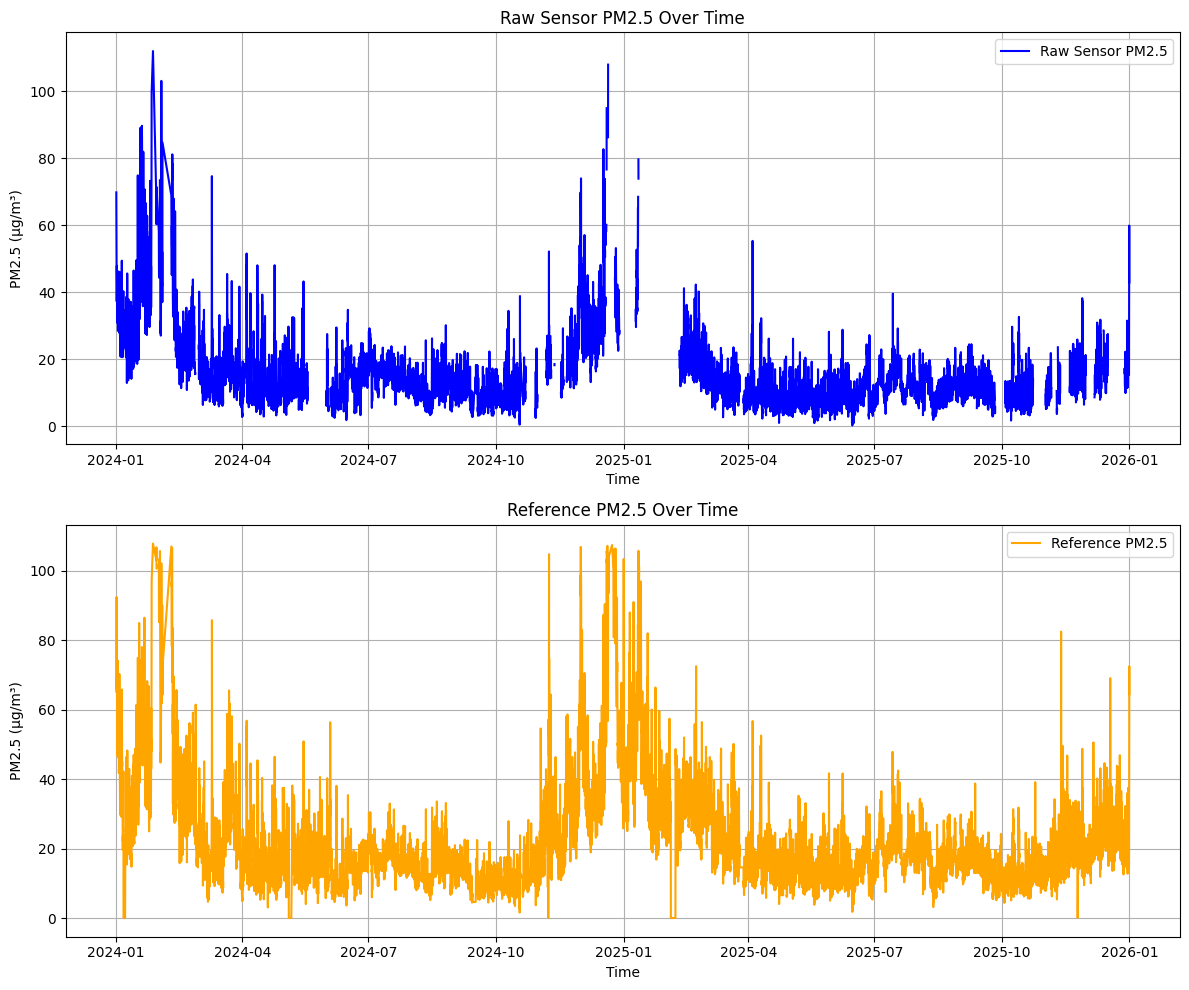

In [ ]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 1, 1)
plt.plot(merged_df['pm25'], label='Raw Sensor PM2.5', color='blue')
plt.xlabel('Time')
plt.ylabel('PM2.5 (µg/m³)')
plt.title('Raw Sensor PM2.5 Over Time')
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(merged_df['PM25'], label='Reference PM2.5', color='orange')
plt.xlabel('Time')
plt.ylabel('PM2.5 (µg/m³)')
plt.title('Reference PM2.5 Over Time')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('raw_pm25_time_series.png', dpi=700)
plt.show()

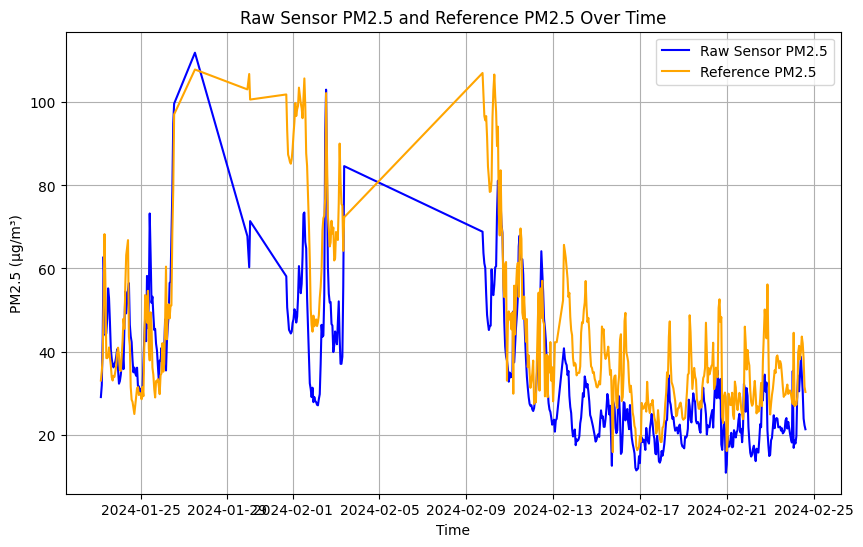

In [ ]:

plt.figure(figsize=(10, 6))

subset = merged_df.iloc[500:1000]

plt.plot(subset['pm25'], label='Raw Sensor PM2.5', color='blue')
plt.plot(subset['PM25'], label='Reference PM2.5', color='orange')
plt.xlabel('Time')
plt.ylabel('PM2.5 (µg/m³)')
plt.title('Raw Sensor PM2.5 and Reference PM2.5 Over Time')
plt.legend()
plt.grid(True)
plt.savefig('raw_pm25_time_series_subset.png', dpi=700)
plt.show()


In [ ]:
max_pos = merged_df['PM25'].idxmax()
max_loc = merged_df.index.get_loc(max_pos)

merged_df.iloc[max(0, max_loc - 10): min(len(merged_df), max_loc + 11)]

,pm25,sample_rh,sample_temp,PM25
timestamp,,,,
2024-01-26 04:00:00+00:00,35.446767,84.651833,27.945167,60.44977
2024-01-26 05:00:00+00:00,42.369750,84.876667,27.665500,42.95821
2024-01-26 06:00:00+00:00,46.087033,84.829833,27.396000,50.16409
2024-01-26 07:00:00+00:00,48.949517,80.248500,28.255500,51.38672
2024-01-26 08:00:00+00:00,56.507983,68.357000,30.780667,47.98913
2024-01-26 09:00:00+00:00,56.810883,57.327167,33.254667,51.00736
2024-01-26 10:00:00+00:00,67.868017,50.252000,34.695167,51.12852
2024-01-26 11:00:00+00:00,78.580267,42.815333,35.935833,68.50101
2024-01-26 12:00:00+00:00,94.948817,27.939500,38.002333,78.83096


In [ ]:
merged_df.dropna(inplace=True)


In [ ]:
print(merged_df.isna().sum())


pm25           0
sample_rh      0
sample_temp    0
PM25           0
dtype: int64


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error



print("R2:", r2_score(merged_df['PM25'], merged_df['pm25']))
print("MAE:", mean_absolute_error(merged_df['PM25'], merged_df['pm25']))
print("RMSE:", root_mean_squared_error(merged_df['PM25'], merged_df['pm25']))


R2: 0.5580772524685484
MAE: 6.221306418683423
RMSE: 8.916936249589217


## TRAIN THE MODEL

In [ ]:
merged_df['rolling_mean_pm25'] = merged_df['pm25'].rolling(window=3).mean()
merged_df['rolling_std_pm25'] = merged_df['pm25'].rolling(window=3).std()

# set the first 2 values of rolling mean and std to the original pm25 values to avoid NaN
merged_df['rolling_mean_pm25'].iloc[:2] = merged_df['pm25'].iloc[:2]
merged_df['rolling_std_pm25'].iloc[:2] = 0


In [ ]:
# use hour_max and month_max to get max pm25 value for each month and hour

In [ ]:
merged_df['hour_of_day'] = merged_df.index.hour
merged_df['day_of_week'] = merged_df.index.dayofweek

dry_months = {11, 12, 1, 2, 3, 4}
merged_df = merged_df.copy()
merged_df['month'] = merged_df.index.month
merged_df['season'] = merged_df['month'].apply(lambda m: 'dry' if m in dry_months else 'wet')
merged_df['is_dry'] = merged_df['season'].eq('dry').astype(int)


if 'precip' in merged_df.columns:
    precip_threshold = 1.0   # mm per interval; adjust as needed
    merged_df['is_dry_precip'] = (merged_df['precip'] < precip_threshold).astype(int)


merged_df[['month','season','is_dry']].groupby('season').size()


season
dry    5888
wet    7669
dtype: int64

In [ ]:
merged_df = merged_df.copy()

# month-based (tune months for your region)
harmattan_months = {11, 12, 1, 2, 3}
merged_df['month'] = merged_df.index.month
merged_df['is_harmattan_month'] = merged_df['month'].isin(harmattan_months).astype(int)

# rolling-climatology anomaly (30 days * 24 hours window, require hourly data)
window_hours = 24 * 30
merged_df['pm25_roll_mean'] = merged_df['pm25'].rolling(window=window_hours, min_periods=24).mean()
merged_df['pm25_roll_std']  = merged_df['pm25'].rolling(window=window_hours, min_periods=24).std(ddof=0).replace(0, np.nan)
merged_df['pm25_z'] = (merged_df['pm25'] - merged_df['pm25_roll_mean']) / merged_df['pm25_roll_std']

# flags (tune thresholds)
merged_df['pm_spike'] = (merged_df['pm25_z'] > 1.5).astype(int)       # anomalously high PM
merged_df['low_rh']   = (merged_df['sample_rh'] < 30).astype(int)     # dry air proxy

# combined indicator (sum gives intensity)
merged_df['harmattan_score'] = merged_df[['is_harmattan_month','pm_spike','low_rh']].fillna(0).sum(axis=1)
merged_df['is_harmattan'] = ((merged_df['is_harmattan_month']==1) & ((merged_df['pm_spike']==1) | (merged_df['low_rh']==1))).astype(int)

# result
sensor_hourly_harmattan = merged_df.drop(columns=['pm25_roll_mean','pm25_roll_std'])
sensor_hourly_harmattan

,pm25,sample_rh,sample_temp,PM25,rolling_mean_pm25,rolling_std_pm25,hour_of_day,day_of_week,month,season,is_dry,is_harmattan_month,pm25_z,pm_spike,low_rh,harmattan_score,is_harmattan
timestamp,,,,,,,,,,,,,,,,,
2024-01-01 01:00:00+00:00,69.789517,76.832333,29.369667,65.25208,69.789517,0.000000,1,0,1,dry,1,1,NaN,0,0,1,0
2024-01-01 06:00:00+00:00,41.240333,82.414500,27.910833,92.49136,41.240333,0.000000,6,0,1,dry,1,1,NaN,0,0,1,0
2024-01-01 07:00:00+00:00,41.700317,78.874333,28.933167,88.84293,50.910056,16.351710,7,0,1,dry,1,1,NaN,0,0,1,0
2024-01-01 08:00:00+00:00,37.260567,70.839833,31.121500,85.10537,40.067072,2.441363,8,0,1,dry,1,1,NaN,0,0,1,0
2024-01-01 09:00:00+00:00,39.383229,61.133125,33.364167,73.48060,39.448038,2.220584,9,0,1,dry,1,1,NaN,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-31 19:00:00+00:00,58.537733,66.222000,29.610667,31.69287,35.665339,21.734397,19,2,12,dry,1,1,8.113622,1,0,2,1
2025-12-31 20:00:00+00:00,58.508450,66.331667,29.024500,64.93999,50.073650,14.634870,20,2,12,dry,1,1,7.751188,1,0,2,1
2025-12-31 21:00:00+00:00,59.890283,69.593000,28.316500,68.67265,58.978822,0.789484,21,2,12,dry,1,1,7.653912,1,0,2,1


In [ ]:
feature_cols = ['pm25', 'sample_temp', 'sample_rh', 'hour_of_day', 'day_of_week']
X = merged_df[feature_cols]
y = merged_df['PM25']

print("Feature Matrix X (first 5 rows):")
display(X.head())

print("\nTarget Vector y (first 5 rows):")
display(y.head())

Feature Matrix X (first 5 rows):


,pm25,sample_temp,sample_rh,hour_of_day,day_of_week
timestamp,,,,,
2024-01-01 01:00:00+00:00,69.789517,29.369667,76.832333,1,0
2024-01-01 06:00:00+00:00,41.240333,27.910833,82.414500,6,0
2024-01-01 07:00:00+00:00,41.700317,28.933167,78.874333,7,0
2024-01-01 08:00:00+00:00,37.260567,31.121500,70.839833,8,0
2024-01-01 09:00:00+00:00,39.383229,33.364167,61.133125,9,0



Target Vector y (first 5 rows):


timestamp
2024-01-01 01:00:00+00:00    65.25208
2024-01-01 06:00:00+00:00    92.49136
2024-01-01 07:00:00+00:00    88.84293
2024-01-01 08:00:00+00:00    85.10537
2024-01-01 09:00:00+00:00    73.48060
Name: PM25, dtype: float64

In [ ]:
merged_df['pm25_rh_interaction'] = merged_df['pm25'] * merged_df['sample_rh']
display(merged_df[['pm25', 'sample_rh', 'pm25_rh_interaction']].head())

,pm25,sample_rh,pm25_rh_interaction
timestamp,,,
2024-01-01 01:00:00+00:00,69.789517,76.832333,5362.091408
2024-01-01 06:00:00+00:00,41.240333,82.414500,3398.801451
2024-01-01 07:00:00+00:00,41.700317,78.874333,3289.084677
2024-01-01 08:00:00+00:00,37.260567,70.839833,2639.532333
2024-01-01 09:00:00+00:00,39.383229,61.133125,2407.619872


In [ ]:
feature_cols = ['pm25', 'sample_temp', 'sample_rh', 'hour_of_day', 'day_of_week', 'rolling_mean_pm25', 'rolling_std_pm25', 'pm25_rh_interaction', 'is_harmattan_month', 'harmattan_score', 'is_harmattan']
X = merged_df[feature_cols]
y = merged_df['PM25']

print("Updated Feature Matrix X (first 5 rows):")
display(X.head())

print("\nTarget Vector y (first 5 rows):")
display(y.head())

Updated Feature Matrix X (first 5 rows):


,pm25,sample_temp,sample_rh,hour_of_day,day_of_week,rolling_mean_pm25,rolling_std_pm25,pm25_rh_interaction,is_harmattan_month,harmattan_score,is_harmattan
timestamp,,,,,,,,,,,
2024-01-01 01:00:00+00:00,69.789517,29.369667,76.832333,1,0,69.789517,0.000000,5362.091408,1,1,0
2024-01-01 06:00:00+00:00,41.240333,27.910833,82.414500,6,0,41.240333,0.000000,3398.801451,1,1,0
2024-01-01 07:00:00+00:00,41.700317,28.933167,78.874333,7,0,50.910056,16.351710,3289.084677,1,1,0
2024-01-01 08:00:00+00:00,37.260567,31.121500,70.839833,8,0,40.067072,2.441363,2639.532333,1,1,0
2024-01-01 09:00:00+00:00,39.383229,33.364167,61.133125,9,0,39.448038,2.220584,2407.619872,1,1,0



Target Vector y (first 5 rows):


timestamp
2024-01-01 01:00:00+00:00    65.25208
2024-01-01 06:00:00+00:00    92.49136
2024-01-01 07:00:00+00:00    88.84293
2024-01-01 08:00:00+00:00    85.10537
2024-01-01 09:00:00+00:00    73.48060
Name: PM25, dtype: float64

In [ ]:
from sklearn.model_selection import train_test_split

train_size = 0.75
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42)


print(f"\nTraining data shape (X_train): {X_train.shape}")
print(f"Training data shape (y_train): {y_train.shape}")
print(f"Testing data shape (X_test): {X_test.shape}")
print(f"Testing data shape (y_test): {y_test.shape}")




Training data shape (X_train): (10167, 11)
Training data shape (y_train): (10167,)
Testing data shape (X_test): (3390, 11)
Testing data shape (y_test): (3390,)


In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=30,
    random_state=42,
    min_samples_leaf=1,
    max_features=1.0,
    n_jobs = 10
)

model.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,30
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators":[200,500],
    "max_depth":[10,20,30],
    "min_samples_leaf": [1, 2, 4]

}

grid = GridSearchCV(model, params, cv=5, n_jobs=10)
grid.fit(X_train,y_train)

BrokenProcessPool: A task has failed to un-serialize. Please ensure that the arguments of the function are all picklable.

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

pred = model.predict(X_test)

print("R2:", r2_score(y_test, pred))

print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", root_mean_squared_error(y_test, pred))


R2: 0.900161132498033
MAE: 1.9026414353392338
RMSE: 4.336300613642636


In [ ]:
grid_pred = grid.predict(X_test)

print("R2:", r2_score(y_test, grid_pred))
print("MAE:", mean_absolute_error(y_test, grid_pred))
print("RMSE:", root_mean_squared_error(y_test, grid_pred))

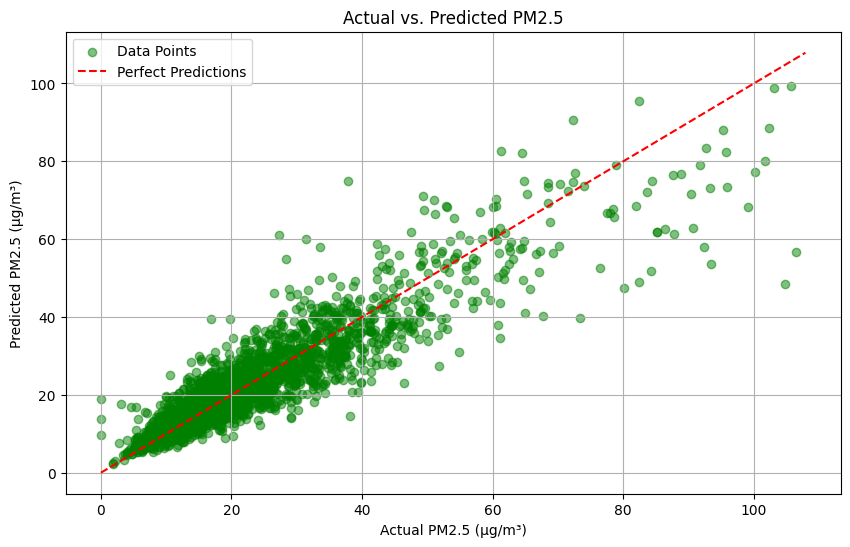

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, pred, alpha=0.5, color='green')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  # Line for perfect predictions
plt.legend(['Data Points', 'Perfect Predictions'])
plt.xlabel('Actual PM2.5 (µg/m³)')
plt.ylabel('Predicted PM2.5 (µg/m³)')
plt.title('Actual vs. Predicted PM2.5')
plt.grid(True)
plt.show()


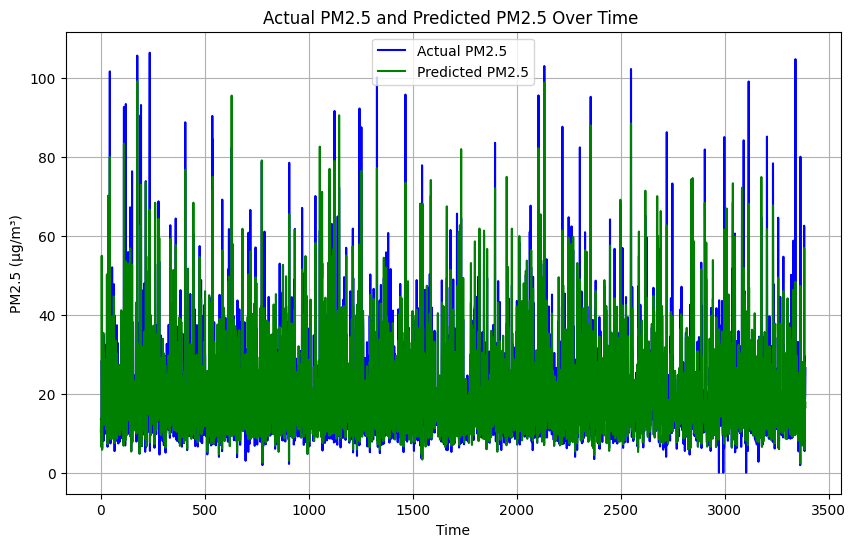

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(y_test.values, label='Actual PM2.5', color='blue')
plt.plot(pred, label='Predicted PM2.5', color='green') 
plt.xlabel('Time')
plt.ylabel('PM2.5 (µg/m³)')
plt.title('Actual PM2.5 and Predicted PM2.5 Over Time ')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# python
# 1) residual diagnostics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)
res = y_test - pred

plt.figure(figsize=(6,4))
plt.scatter(pred, res, alpha=0.6)
plt.axhline(0, color='k', lw=1)
plt.xlabel('predicted')
plt.ylabel('residual')
plt.title('Residuals vs predicted')

# 2) identify high-residual rows
err_df = pd.DataFrame({'y': y_test, 'pred': pred, 'abs_err': np.abs(res)})
err_df.sort_values('abs_err', ascending=False).head(10)

# 3) try target transform if skew/heteroskedastic
y_train_log = np.log1p(y_train)   # inverse: np.expm1(pred)
pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),("poly", PolynomialFeatures(degree=2, include_bias=False)),("scaler", StandardScaler()), ("model", Ridge())])
pipe.fit(X_train, y_train_log)
r2_log = r2_score(y_test, np.expm1(pipe.predict(X_test)))

# 4) add polynomial features (careful with dimensionality)
poly_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=1.0))
])
scores = cross_val_score(poly_pipe, X, y, cv=5, scoring='r2', n_jobs=-1)

# 5) hyperparameter search for a tree-based model
param_grid = {'n_estimators':[100,300], 'max_depth':[6,12,None]}
gs = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
gs.fit(X_train, y_train)
best = gs.best_estimator_
cv_r2 = cross_val_score(best, X, y, cv=5, scoring='r2').mean()

# 6) robust outlier handling: remove rows with huge residuals and re-fit
threshold = np.percentile(np.abs(res), 95)
keep_mask = np.abs(res) <= threshold
X_retrain = X_test.loc[keep_mask] if hasattr(X_test, 'loc') else X_test[np.where(keep_mask)]
y_retrain = y_test.loc[keep_mask] if hasattr(y_test, 'loc') else y_test[np.where(keep_mask)]
model.fit(X_retrain, y_retrain)
r2_after = r2_score(y_test, model.predict(X_test))

# 7) evaluate with cross-validated R2 to avoid optimistic estimates
cv_final = cross_val_score(best, X, y, cv=5, scoring='r2').mean()

In [ ]:
model

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
import joblib



In [ ]:
joblib.dump(model, 'random_forest_pm25_model_update2.joblib')

['random_forest_pm25_model_update2.joblib']

# Trying to add the rainfall parameters as a feature

10 day rainfall [mm] (rfh)

rainfall 1-month rolling aggregation [mm] (r1h)

rainfall 3-month rolling aggregation [mm] (r3h)

rainfall long term average [mm] (rfh_avg)

rainfall 1-month rolling aggregation long term average [mm] (r1h_avg)

rainfall 3-month rolling aggregation long term average [mm] (r3h_avg)

rainfall anomaly [%] (rfq)

rainfall 1-month anomaly [%] (r1q)

rainfall 3-month anomaly [%] (r3q)

In [ ]:
rainfall_df = pd.read_csv('rainfall/gha-rainfall-subnat-5ytd.csv')

rainfall_df

,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
0,2022-01-01,1,900854,GH02,798.0,1.631579,3.642774,7.929824,18.889140,244.740620,215.708100,76.729760,54.124283,113.15426,final
1,2022-01-11,1,900854,GH02,798.0,1.457394,2.760902,7.310777,12.792106,189.581470,156.999300,83.204160,69.192350,120.11254,final
2,2022-01-21,1,900854,GH02,798.0,1.486216,6.756349,4.575188,13.160025,118.897224,100.935840,55.172020,52.726734,116.95497,final
3,2022-02-01,1,900854,GH02,798.0,2.566416,12.038555,5.510025,21.555805,86.815770,88.258560,44.407616,39.577130,98.45292,final
4,2022-02-11,1,900854,GH02,798.0,17.488722,19.411488,21.541353,38.206390,49.131580,88.555980,92.123520,61.429234,57.86010,final
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33970,2026-01-21,2,1009550,GH1003,26.0,3.692308,4.837180,12.346153,10.897436,131.192300,70.294870,88.361786,109.112890,180.87860,final
33971,2026-02-01,2,1009550,GH1003,26.0,38.269230,7.719231,45.000000,15.658975,139.076920,60.089745,340.187470,242.025570,221.35120,prelim
33972,2026-02-11,2,1009550,GH1003,26.0,23.576923,12.817948,65.538460,25.374360,143.115390,60.175640,160.382810,232.230290,227.25572,prelim
33973,2026-02-21,2,1009550,GH1003,26.0,2.730769,13.714103,64.576920,34.251280,109.884605,62.466667,41.309853,177.260240,170.28351,prelim


In [ ]:
rainfall_df = rainfall_df[rainfall_df['PCODE'] == 'GH07']

In [ ]:
rainfall_df['date'] = pd.to_datetime(rainfall_df['date'], errors='coerce')

C:\Users\Hughe\AppData\Local\Temp\ipykernel_17664\195218613.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rainfall_df['date'] = pd.to_datetime(rainfall_df['date'], errors='coerce')


In [ ]:
# rainfall_df.reset_index(drop=True)
# rainfall_df.drop(columns=['timestamp'], inplace=True)
# rainfall_df.reset_index(inplace=True)

C:\Users\Hughe\AppData\Local\Temp\ipykernel_17664\423611756.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rainfall_df.drop(columns=['timestamp'], inplace=True)


In [ ]:
rainfall_df

,level_0,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
0,0,2022-01-01,1,900858,GH07,115.0,2.008696,4.421449,17.913044,20.565508,177.66956,161.618550,74.390840,89.624830,109.633385,final
1,1,2022-01-11,1,900858,GH07,115.0,1.347826,3.099130,16.417390,15.375942,149.99998,126.663770,78.376630,105.111170,117.724100,final
2,2,2022-01-21,1,900858,GH07,115.0,1.765217,6.919710,5.121739,14.440290,97.46957,96.608116,56.756557,52.065784,100.847820,final
3,3,2022-02-01,1,900858,GH07,115.0,2.660870,7.671884,5.773913,17.690725,55.47826,84.467830,60.455643,47.481570,67.597780,final
4,4,2022-02-11,1,900858,GH07,115.0,12.130435,14.047246,16.556522,28.638840,50.53913,82.094780,89.936554,64.082245,63.768612,final
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,146,2026-01-21,1,900858,GH07,115.0,4.547826,6.919710,41.321735,14.440290,245.53912,96.608116,80.101166,238.277010,246.573930,final
147,147,2026-02-01,1,900858,GH07,115.0,33.965218,7.671884,57.834785,17.690725,233.49567,84.467830,307.493470,276.918370,266.571400,prelim
148,148,2026-02-11,1,900858,GH07,115.0,14.913043,14.047246,53.426086,28.638840,209.06953,82.094780,104.545530,173.686390,245.789170,prelim
149,149,2026-02-21,1,900858,GH07,115.0,9.521739,11.823769,58.400000,33.542900,171.13043,75.704926,86.316800,164.492030,218.240000,prelim


In [ ]:
# Load the saved Random Forest model
loaded_model = joblib.load('random_forest_pm25_model_update2.joblib')
loaded_model

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
# Make predictions using the loaded model
y_pred = loaded_model.predict(X_test)
y_pred

array([11.48700109, 13.02654167,  6.50834054, ..., 23.1143701 ,
        9.96770883, 13.67802319])

In [ ]:
# Compare predictions with actual values
comparison_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Error': y_test.values - y_pred
})
comparison_df.head(10)

,Actual,Predicted,Error
0,10.323310,11.487001,-1.163691
1,13.724590,13.026542,0.698048
2,7.820983,6.508341,1.312642
3,15.156500,15.293586,-0.137086
4,28.408330,59.623571,-31.215241
5,22.001010,22.762655,-0.761645
6,6.224121,6.082813,0.141308
7,16.110200,17.200938,-1.090738
8,13.334080,13.952892,-0.618812
9,19.274130,18.334468,0.939662


In [ ]:
# Summary statistics for prediction errors
print("Error Statistics:")
print(f"Mean Error: {comparison_df['Error'].mean():.4f}")
print(f"Std Dev: {comparison_df['Error'].std():.4f}")
print(f"Min Error: {comparison_df['Error'].min():.4f}")
print(f"Max Error: {comparison_df['Error'].max():.4f}")
print(f"MAE: {comparison_df['Error'].abs().mean():.4f}")

Error Statistics:
Mean Error: 0.2119
Std Dev: 4.2506
Min Error: -31.2152
Max Error: 51.2898
MAE: 1.7783


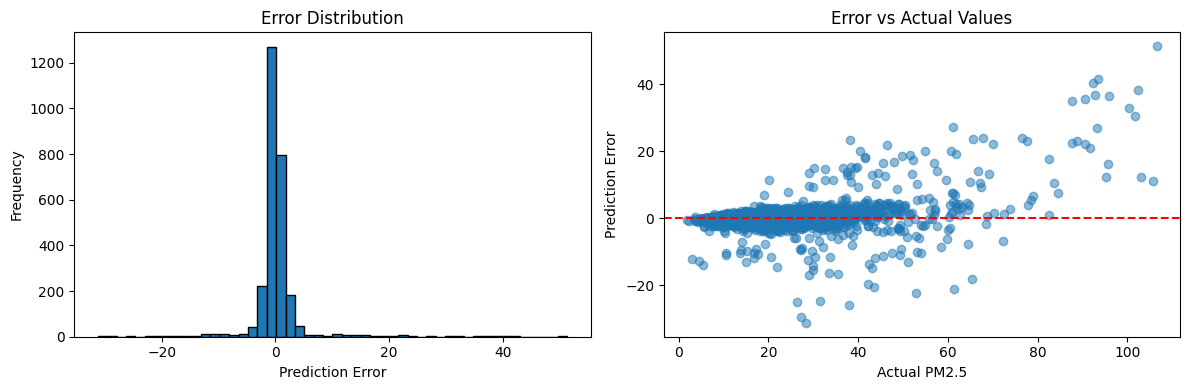

In [ ]:
# Visualize the error distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(comparison_df['Error'], bins=50, edgecolor='black')
axes[0].set_xlabel('Prediction Error')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Error Distribution')
axes[1].scatter(comparison_df['Actual'], comparison_df['Error'], alpha=0.5)
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_xlabel('Actual PM2.5')
axes[1].set_ylabel('Prediction Error')
axes[1].set_title('Error vs Actual Values')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

mae = mean_absolute_error(comparison_df['Actual'], comparison_df['Predicted'])
rmse = root_mean_squared_error(comparison_df['Actual'], comparison_df['Predicted'])
r2 = r2_score(comparison_df['Actual'], comparison_df['Predicted'])

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 1.7783
Root Mean Squared Error (RMSE): 4.2551
R² Score: 0.9039


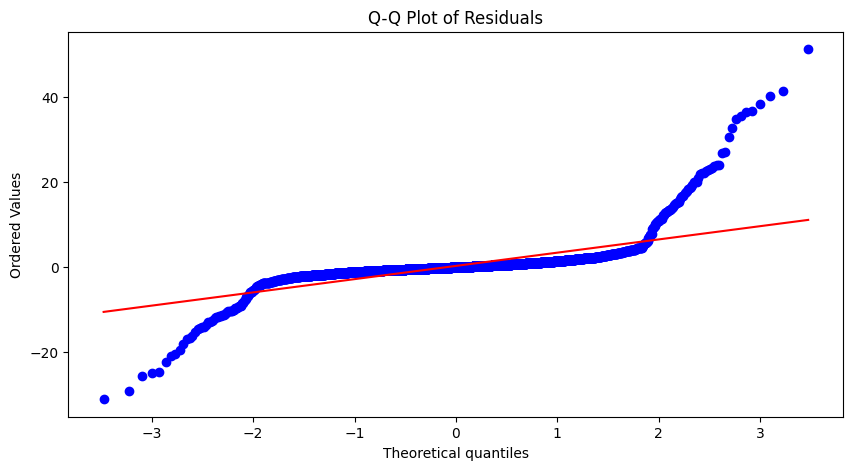

In [ ]:
from scipy import stats

plt.figure(figsize=(10, 5))
stats.probplot(comparison_df['Error'], dist="norm", plot=plt)
plt.title('Q-Q Plot of Residuals')
plt.show()

In [ ]:
# Check the index overlap and any systematic gaps in sensor data
print(f"Sensor date range: {sensor_hourly.index.min()} to {sensor_hourly.index.max()}")
print(f"Reference date range: {ref_df.index.min()} to {ref_df.index.max()}")
print(f"\nOverlapping records: {sensor_hourly.index.isin(ref_df.index).sum()} out of {len(sensor_hourly)}")

Sensor date range: 2024-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00
Reference date range: 2024-01-01 01:00:00+00:00 to 2026-03-07 04:00:00+00:00

Overlapping records: 16851 out of 17544


In [ ]:
# Align sensor_hourly to ref_df's index to handle the 1-hour offset and gaps
sensor_hourly_aligned = sensor_hourly.reindex(ref_df.index)
print(f"Aligned sensor data shape: {sensor_hourly_aligned.shape}")
print(f"Missing values after alignment: {sensor_hourly_aligned.isna().sum().sum()}")

Aligned sensor data shape: (18342, 3)
Missing values after alignment: 14355


## USING NEURAL NETWORKS

In [ ]:
# python
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Build pipeline: scaler + MLP
pipeline = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(100, 50),
                 activation='relu',
                 solver='adam',
                 early_stopping=True,
                 validation_fraction=0.1,
                 max_iter=500,
                 random_state=42)
)

# Fit
pipeline.fit(X_train, y_train)

# Predict and evaluate
y_pred = pipeline.predict(X_test)
metrics = {
    "r2": r2_score(y_test, y_pred),
    "rmse": np.sqrt(mean_squared_error(y_test, y_pred))
}

# Return useful objects
{
    "model_pipeline": pipeline,
    "y_test": y_test,
    "y_pred": y_pred,
    "metrics": metrics
}

{'model_pipeline': Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('mlpregressor',
                  MLPRegressor(early_stopping=True, hidden_layer_sizes=(100, 50),
                               max_iter=500, random_state=42))]),
 'y_test': timestamp
 2024-09-27 10:00:00+00:00    10.323310
 2025-05-17 21:00:00+00:00    13.724590
 2025-05-21 01:00:00+00:00     7.820983
 2025-08-25 23:00:00+00:00    15.156500
 2024-01-24 14:00:00+00:00    28.408330
                                ...    
 2025-08-12 15:00:00+00:00     5.495748
 2024-02-23 16:00:00+00:00    29.524440
 2025-07-29 02:00:00+00:00    18.639530
 2024-07-19 13:00:00+00:00    20.210530
 2024-03-23 22:00:00+00:00    26.523890
 Name: PM25, Length: 3390, dtype: float64,
 'y_pred': array([14.01864943, 11.47309034,  5.86254426, ..., 15.82591699,
        16.81693127, 20.27068326]),
 'metrics': {'r2': 0.8540606533149836, 'rmse': 5.233396621927465}}

In [ ]:
print(f"R² Score: {metrics['r2']:.4f}")
print(f"RMSE: {metrics['rmse']:.4f}")

R² Score: 0.8541
RMSE: 5.2334


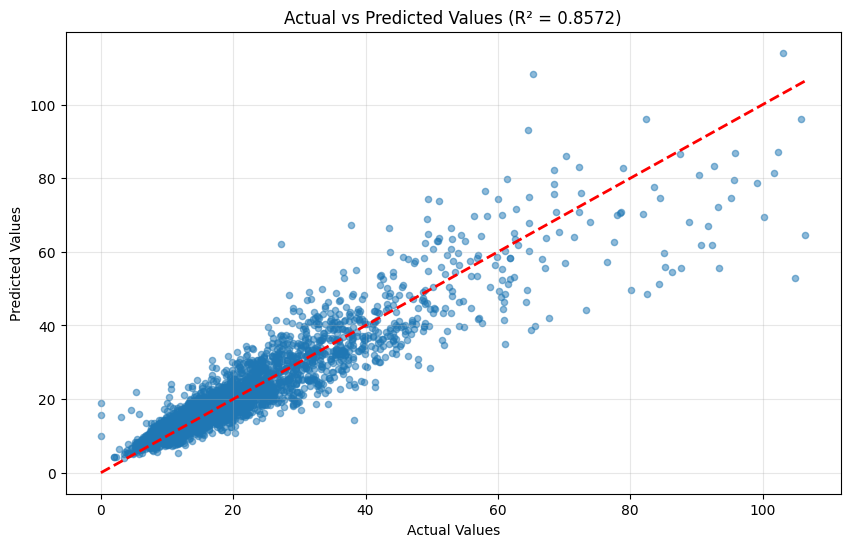

In [ ]:
# Plot actual vs predicted values to visualize model performance
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, s=20)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values (R² = 0.8572)')
plt.grid(True, alpha=0.3)
plt.show()

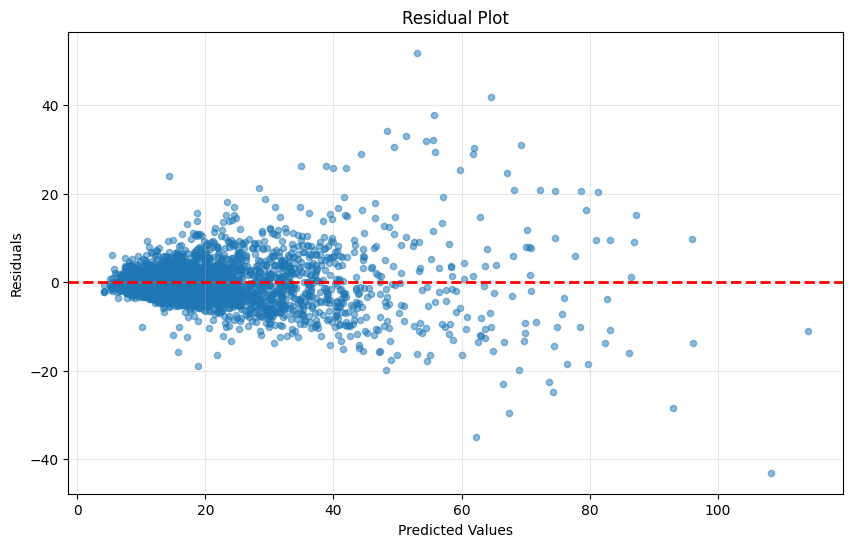

In [ ]:
# Calculate and analyze residuals
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.5, s=20)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Analyze residual statistics
print(f"Residual Mean: {residuals.mean():.6f}")
print(f"Residual Std Dev: {residuals.std():.4f}")
print(f"Residual Min: {residuals.min():.4f}")
print(f"Residual Max: {residuals.max():.4f}")

Residual Mean: -0.264234
Residual Std Dev: 5.2275
Residual Min: -43.0525
Residual Max: 51.8045


In [ ]:
from sklearn.utils import validation
# Chronological split, time-series CV, randomized hyperparameter search for an MLP pipeline
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import numpy as np
import pandas as pd

# 1) chronological split (no random shuffle)
split_idx = int(len(X) * 0.75)
X_train_ts, X_test_ts = X.iloc[:split_idx], X.iloc[split_idx:]
y_train_ts, y_test_ts = y.iloc[:split_idx], y.iloc[split_idx:]

# 2) pipeline
pipe = make_pipeline(StandardScaler(), MLPRegressor(early_stopping=True, random_state=42, max_iter=1000))

# 3) search space (tune these)
param_dist = {
    "mlpregressor__hidden_layer_sizes": [(64,), (100, 50), (100, 50, 25), (128,), (128,64), (256,128,64)],
    "mlpregressor__alpha": [1e-5, 1e-4, 1e-3, 1e-2],
    "mlpregressor__batch_size": [64, 256, 'auto'],
    "mlpregressor__activation": ['relu'],
    "mlpregressor__solver": ['adam'],
}

# 4) time-series CV and randomized search
tscv = TimeSeriesSplit(n_splits=5)
search = RandomizedSearchCV(pipe, param_distributions=param_dist, n_iter=24,
                            cv=tscv, scoring='neg_root_mean_squared_error',
                            n_jobs=-1, validation_fraction=0.1, random_state=42, verbose=1)

search.fit(X_train_ts, y_train_ts)

# 5) evaluate on holdout
best = search.best_estimator_
y_pred = best.predict(X_test_ts)
rmse = root_mean_squared_error(y_test_ts, y_pred)
r2 = r2_score(y_test_ts, y_pred)

# 6) permutation importance (on holdout)
perm = permutation_importance(best, X_test_ts, y_test_ts, n_repeats=20, n_jobs=-1, random_state=42)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

# return useful results
{
    "best_params": search.best_params_,
    "rmse": float(rmse),
    "r2": float(r2),
    "feature_importance": imp,
    "estimator": best,
    "y_test": y_test_ts,
    "y_pred": y_pred
}

Fitting 5 folds for each of 24 candidates, totalling 120 fits


{'best_params': {'mlpregressor__solver': 'adam',
  'mlpregressor__hidden_layer_sizes': (100, 50, 25),
  'mlpregressor__batch_size': 64,
  'mlpregressor__alpha': 0.001,
  'mlpregressor__activation': 'tanh'},
 'rmse': 4.608963866290084,
 'r2': 0.4933634473464401,
 'feature_importance': rolling_mean_pm25      2.219470
 sample_rh              0.318662
 sample_temp            0.249333
 pm25_rh_interaction    0.154847
 hour_of_day            0.141029
 harmattan_score        0.106592
 rolling_std_pm25       0.070360
 pm25                   0.029258
 day_of_week            0.017323
 is_harmattan          -0.013651
 is_harmattan_month    -0.025122
 dtype: float64,
 'estimator': Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('mlpregressor',
                  MLPRegressor(activation='tanh', alpha=0.001, batch_size=64,
                               early_stopping=True,
                               hidden_layer_sizes=(100, 50, 25), max_iter=1000,
                        

In [ ]:
# Compare time-series CV model vs previous random-split model
print("Time-Series Split Model (Cell 65):")
print(f"R² Score: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print("\nBest Parameters:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")

Time-Series Split Model (Cell 65):
R² Score: 0.4934
RMSE: 4.6090

Best Parameters:
  mlpregressor__solver: adam
  mlpregressor__hidden_layer_sizes: (100, 50, 25)
  mlpregressor__batch_size: 64
  mlpregressor__alpha: 0.001
  mlpregressor__activation: tanh


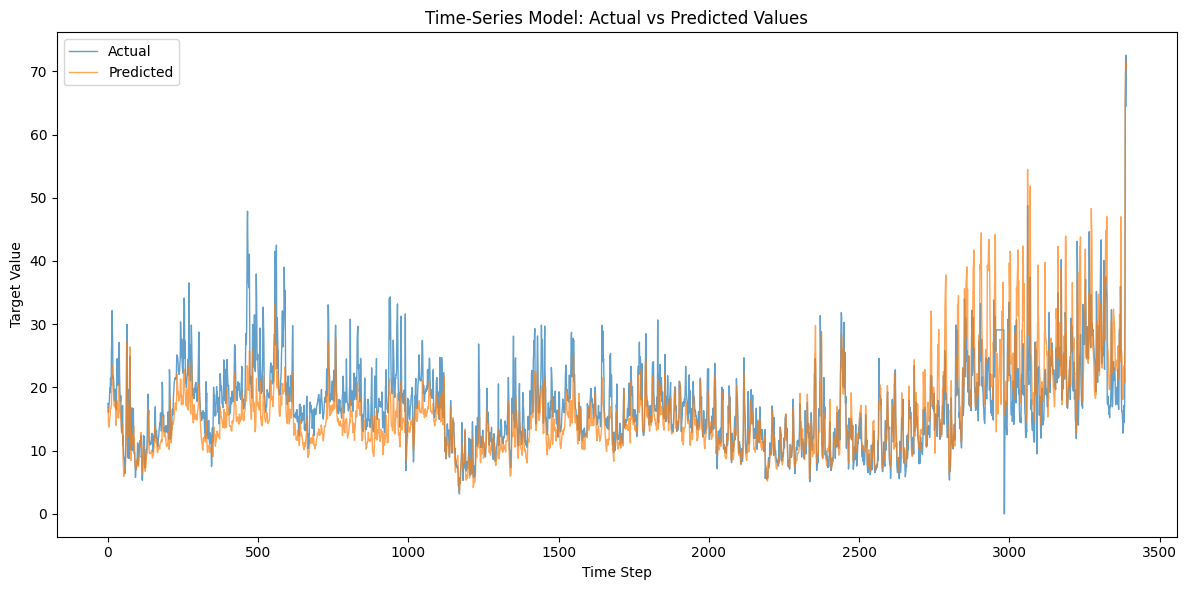

In [ ]:
# Plot time-series predictions vs actuals to validate temporal performance
plt.figure(figsize=(12, 6))
plt.plot(range(len(y_test_ts)), y_test_ts.values, label='Actual', alpha=0.7, linewidth=1)
plt.plot(range(len(y_test_ts)), y_pred, label='Predicted', alpha=0.7, linewidth=1)
plt.xlabel('Time Step')
plt.ylabel('Target Value')
plt.title('Time-Series Model: Actual vs Predicted Values')
plt.legend()
plt.savefig('time_series_actual_vs_predicted_neural_network.png', dpi=700)
plt.tight_layout()
plt.show()

In [ ]:
# python
# Retrain baseline on same chronological train set, run corrected randomized search, compare on same holdout
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# 1) baseline trained on X_train_ts (same as search)
baseline = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(100, 50),
                 activation='relu',
                 solver='adam',
                 early_stopping=True,
                 validation_fraction=0.1,
                 max_iter=500,
                 random_state=42)
)
baseline.fit(X_train_ts, y_train_ts)
y_pred_baseline = baseline.predict(X_test_ts)
metrics_baseline = {"r2": r2_score(y_test_ts, y_pred_baseline),
                    "rmse": np.sqrt(mean_squared_error(y_test_ts, y_pred_baseline))}

# 2) corrected RandomizedSearchCV (validation_fraction set in estimator; avoid invalid kwargs on RandomizedSearchCV)
pipe = make_pipeline(StandardScaler(), MLPRegressor(early_stopping=True, validation_fraction=0.1, max_iter=500, random_state=42))
tscv = TimeSeriesSplit(n_splits=5)
search = RandomizedSearchCV(pipe, param_distributions=param_dist, n_iter=48, cv=tscv,
                            scoring='neg_root_mean_squared_error', n_jobs=1, random_state=42, verbose=1)
search.fit(X_train_ts, y_train_ts)
best = search.best_estimator_
y_pred_search = best.predict(X_test_ts)
metrics_search = {"r2": r2_score(y_test_ts, y_pred_search),
                  "rmse": np.sqrt(mean_squared_error(y_test_ts, y_pred_search))}

# 3) results
{"baseline": metrics_baseline, "search_best": metrics_search, "search_best_params": search.best_params_}

NameError: name 'X_train_ts' is not defined

In [ ]:
for x, y in new_data:
    prediction = model(x)
    loss = criterion(prediction, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()